<h1 style="text-align: center;">
Diabetes Progression Prediction Using Machine Learning
</h1>

# Part 1 — Data understanding, EDA and split

## Step 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import (r2_score, mean_absolute_error,
                             mean_absolute_percentage_error,
                             accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)
RANDOM_STATE = 42


## Step 2: Load and View the Dataset

The dataset contains **442 records**, **10 features (X)**, and **1 target (y)**.

- **Features (X):** Age, sex, BMI, blood pressure, and serum measurements.
- **Target (y):** Diabetes disease progression one year after baseline.

We use the features to predict the target.

In [5]:
diabetes = load_diabetes(as_frame=True)  # scaled=True is default
X = diabetes.data.copy()
y = diabetes.target.copy()
df = pd.concat([X, y.rename('progression')], axis=1)
print('X shape:', X.shape)
print('y shape:', y.shape)
display(df.head())
print(diabetes.DESCR[:1600])

X shape: (442, 10)
y shape: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

## Step 3: Frame the Problem and Metrics

Our goal is to predict diabetes disease progression
using patient features such as BMI, age, and blood pressure.

This is a regression problem because the target is numerical.

We evaluate the models using:

- **R²:** Measures how well the model explains the data.
- **MAE:** Measures the average prediction error.
- **MAPE:** Measures the average percentage error.

In medical screening, false negatives are important because
the model could miss high-risk patients.

## Step 4: Dataset Statistics and Missing Values

We check the dataset's size, statistics, missing values, and duplicates to understand the data and see if cleaning is needed.

In [6]:
print(df.shape)
print(df.dtypes)
display(df.describe().T)
print('Missing values per column:')
print(df.isna().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Min target:', y.min())


(442, 11)
age            float64
sex            float64
bmi            float64
bp             float64
s1             float64
s2             float64
s3             float64
s4             float64
s5             float64
s6             float64
progression    float64
dtype: object


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.268604e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


Missing values per column:
age            0
sex            0
bmi            0
bp             0
s1             0
s2             0
s3             0
s4             0
s5             0
s6             0
progression    0
dtype: int64
Duplicate rows: 0
Min target: 25.0


### Histogram Analysis

The histograms show that most BMI, BP, and s5 values
are concentrated near zero.

The progression scores are spread over a wider range,
with fewer patients having very high scores.

These graphs help us understand the data distribution.

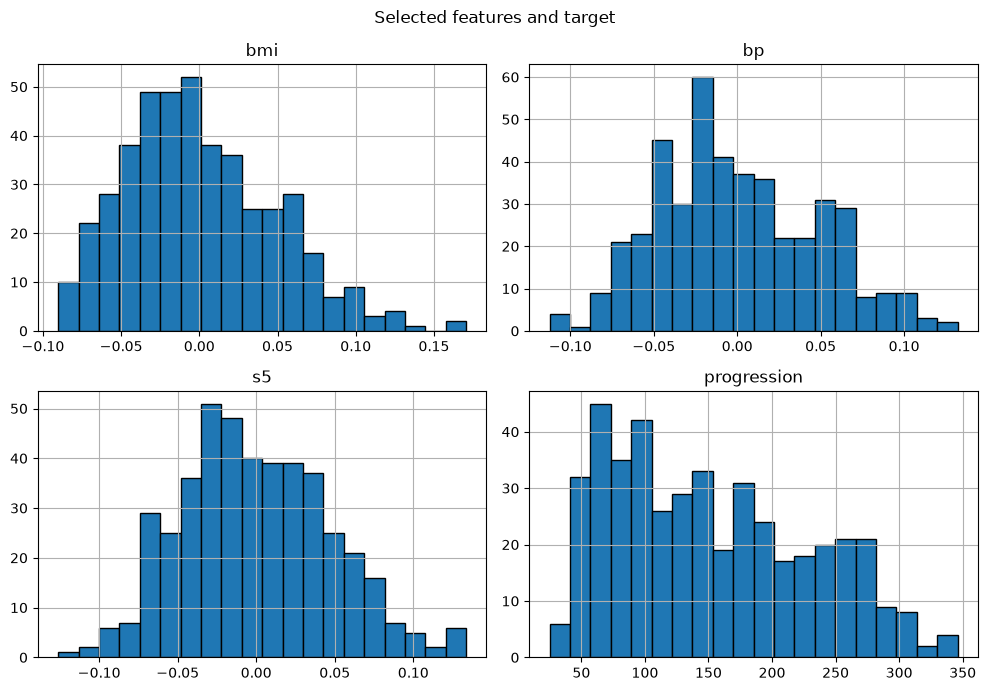

In [8]:
df[["bmi", "bp", "s5", "progression"]].hist(bins=20, figsize=(10,7), edgecolor='black')
plt.suptitle("Selected features and target")
plt.tight_layout()
plt.show()

## Step 6. Required scatter plots
in here, i use scatter plots to understand the relationship between patient features and diabetes progression.

The scatter plots show positive relationships between
BMI, BP, s5, and diabetes progression.

BMI and s5 appear to have stronger relationships with
progression than BP.

However, the points are scattered, suggesting that
one feature alone may not predict progression accurately.

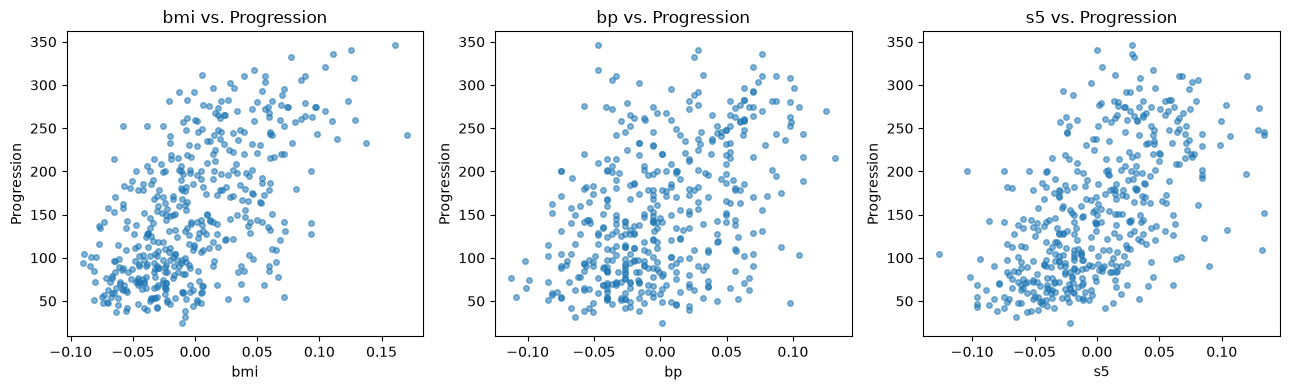

In [22]:
fig, axes=plt.subplots(1, 3, figsize=(13,4))
for ax, feature in zip(axes, ['bmi', 'bp', 's5']):
    ax.scatter(df[feature], df['progression'], alpha=0.55, s=16)
    ax.set(xlabel=feature, ylabel='Progression', title=f'{feature} vs. Progression')
plt.tight_layout()
plt.show()

## Step 7: Correlation Matrix

I use a correlation matrix to understand the relationships between features and diabetes progression.

BMI (0.59) and s5 (0.57) show the strongest positive correlations with progression, while s3 (-0.39) shows a negative correlation.

This helps us identify useful features for prediction.

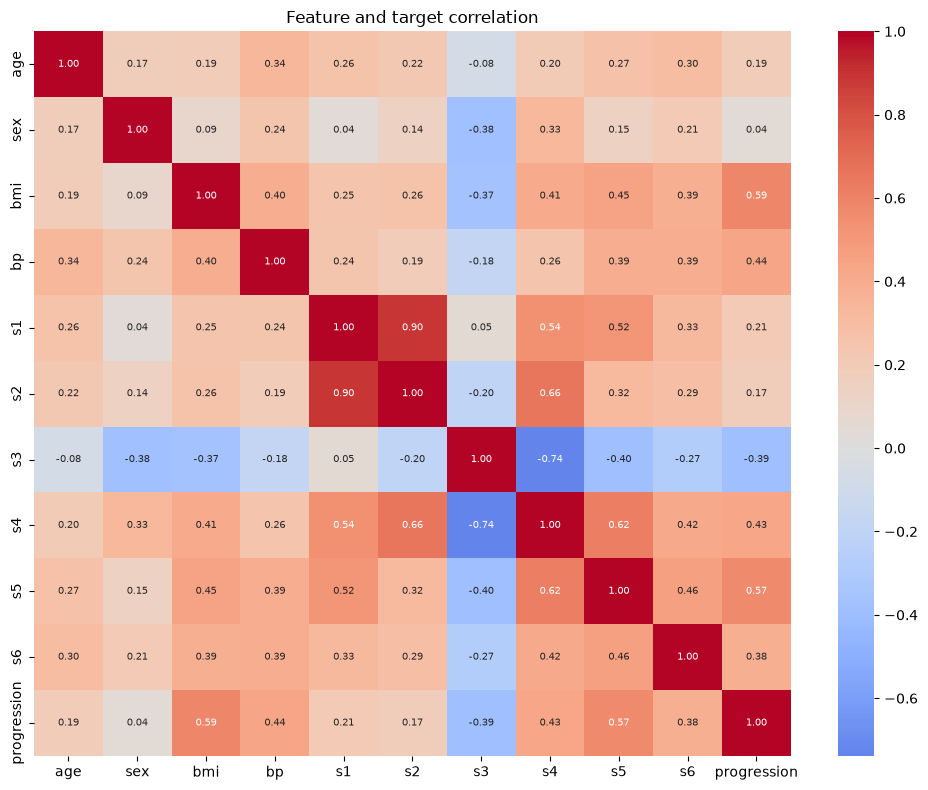

In [32]:
corr=df.corr(numeric_only=True)
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt= '.2f', cmap= 'coolwarm', center=0, annot_kws={'size':7})
plt.title('Feature and target correlation')
plt.tight_layout()
plt.show()

## Step 8: Data Cleaning

The dataset has no missing values or duplicate rows.
All columns contain numerical values, and the features
are already scaled.

Therefore, no additional data cleaning is needed.

# Step 9: Train, Validation, and Test Split

We split the dataset into 75% training, 10% validation,
and 15% testing.

Training data is used to train the model, validation
data helps select the best model, and test data
measures performance on unseen data.

In [33]:
# First reserve 15% as untouched test data.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE)

# Of the remaining 85%, allocate 10/85 to validation.
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=10/85, random_state=RANDOM_STATE)
print('Train:', len(X_train), 'Validation:', len(X_val),
      'Test:', len(X_test))
print('Shares:', len(X_train)/len(X), len(X_val)/len(X),
      len(X_test)/len(X))


Train: 330 Validation: 45 Test: 67
Shares: 0.746606334841629 0.10180995475113122 0.1515837104072398
